# Data Pipeline & Feature Engineering

**Author: Manideep.**

This notebook covers the Week 3 project steps: cataloging the dataset, exploring it, engineering
features from the raw sensor windows, and writing those features to a SageMaker Feature Store
group. It reads the raw/curated S3 data and Athena tables that already exist in this project
(created once, shared by the whole team) and does not modify any existing notebook or any file
under `src/pamap2/`.

The feature-engineering job below **imports the existing `pamap2.features` module** for the
windowing and the accelerometer/gyroscope/heart-rate statistics (`segment`, `make_windows`,
`window_features`) instead of re-writing that logic — `src/pamap2/` is shipped into the
Processing Job container as a dependency so the job script can `import pamap2` directly. The one
genuinely new piece of code here is the magnetometer + signal-magnitude-area features layered on
top of that, since nothing in the existing pipeline computes those.

**What it produces:**
- A windowed feature table — one row per 5.12s sensor window, with `pamap2.features`' existing
  accelerometer/gyroscope/heart-rate statistics, plus new **magnetometer** and
  **signal-magnitude-area** features (hand/chest/ankle).
- That table stored in a SageMaker Feature Store group, `pamap2-har-windows-v2`.
- CSV exports with two different evaluation setups ready to train against:
  - A standard **train / validation / test / production** split.
  - The full table kept with `subject_id` intact, for **Leave-One-Subject-Out (LOSO)**
    cross-validation in the companion notebook (`B_model_training_deployment_monitoring.ipynb`).

Run `1_setup.ipynb` first — this notebook loads `config/project_config.json` for the bucket name,
IAM role, and Athena workgroup/database.

## 1. Bootstrap

In [1]:
import sys, pathlib
PROJECT_ROOT = pathlib.Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import io, json, time
import boto3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sagemaker
from sagemaker.sklearn.estimator import SKLearn as SKLearnFramework
from sagemaker.processing import FrameworkProcessor, ProcessingInput, ProcessingOutput

from src.pamap2.config import load_config, s3_uri

cfg = load_config()
BUCKET = cfg["bucket"]
ROLE = cfg["role_arn"]

boto_session = boto3.Session(region_name=cfg["region"])
sm_session = sagemaker.Session(boto_session=boto_session, default_bucket=BUCKET)
print("Caller:", boto_session.client("sts").get_caller_identity()["Arn"])

s3 = boto_session.client("s3")
sm = boto_session.client("sagemaker")
athena = boto_session.client("athena")

FEATURE_GROUP_NAME = "pamap2-har-windows-v2"
OUTPUT_PREFIX = "features/v2/"
pathlib.Path("scripts").mkdir(exist_ok=True)


sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


Caller: arn:aws:sts::836620944282:assumed-role/AmazonSageMaker-ExecutionRole-20261015T160795/SageMaker


## 2. Explore the data

A quick Athena query against the `curated_pamap2` table: how many sensor readings each subject
contributed per activity. This decides nothing automatically — it's just a look at the data
before engineering features from it, and it shows directly why some activities will be missing
from a held-out subject's evaluation later (not every subject performed every activity).

activity_id,1,2,3,4,5,6,7,9,10,11,12,13,16,17,18,19,20,24
subject_id,,,,,,,,,,,,,,,,,,
101,27187.0,23480.0,21717.0,22253.0,21265.0,23575.0,20265.0,83646.0,0.0,54519.0,15890.0,14899.0,22941.0,23573.0,27114.0,54089.0,0.0,12912.0
102,23430.0,22345.0,25576.0,32533.0,9238.0,25108.0,29739.0,0.0,0.0,0.0,17342.0,15213.0,20683.0,28880.0,0.0,0.0,0.0,13262.0
103,22044.0,28761.0,20533.0,29036.0,0.0,0.0,0.0,0.0,0.0,0.0,10389.0,15275.0,20325.0,27975.0,0.0,0.0,0.0,0.0
104,23047.0,25492.0,24706.0,31932.0,1.0,22699.0,27533.0,0.0,0.0,0.0,16694.0,14285.0,20037.0,24995.0,0.0,0.0,0.0,0.0
105,23699.0,26864.0,22132.0,32033.0,24646.0,24577.0,26271.0,0.0,110883.0,0.0,14281.0,12727.0,24445.0,33034.0,0.0,28488.0,0.0,7733.0
106,23340.0,23041.0,24356.0,25721.0,22825.0,20486.0,26686.0,0.0,61777.0,0.0,13291.0,11272.0,21078.0,37744.0,21786.0,28714.0,0.0,256.0
107,25611.0,12282.0,25751.0,33720.0,3692.0,22680.0,28725.0,0.0,0.0,0.0,17646.0,11618.0,21552.0,29499.0,0.0,0.0,0.0,0.0
108,24165.0,22923.0,25160.0,31533.0,16532.0,25475.0,28888.0,0.0,68725.0,0.0,11683.0,9655.0,24292.0,32990.0,23650.0,41691.0,18126.0,8806.0
109,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,68550.0,0.0,0.0,0.0,0.0,0.0,27328.0,34206.0,28789.0,6391.0


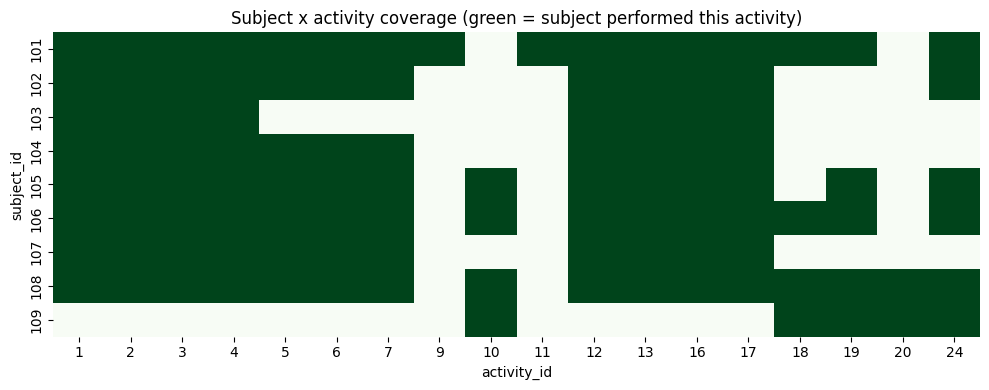

In [2]:
def run_athena(sql, database=None, timeout_s=600):
    query_id = athena.start_query_execution(
        QueryString=sql, WorkGroup=cfg["athena_workgroup"],
        QueryExecutionContext={"Database": database or cfg["glue_database"]})["QueryExecutionId"]
    deadline = time.time() + timeout_s
    while True:
        execution = athena.get_query_execution(QueryExecutionId=query_id)["QueryExecution"]
        state = execution["Status"]["State"]
        if state in ("SUCCEEDED", "FAILED", "CANCELLED"):
            break
        if time.time() > deadline:
            athena.stop_query_execution(QueryExecutionId=query_id)
            raise TimeoutError(f"Athena query exceeded {timeout_s}s")
        time.sleep(1)
    if state != "SUCCEEDED":
        raise RuntimeError(f"{state}: {execution['Status'].get('StateChangeReason')}\n{sql}")
    out_uri = execution["ResultConfiguration"]["OutputLocation"]
    bucket, key = out_uri[len("s3://"):].split("/", 1)
    return pd.read_csv(io.BytesIO(s3.get_object(Bucket=bucket, Key=key)["Body"].read()))

coverage_sql = f"""
SELECT subject_id, activity_id, COUNT(*) AS n_rows
FROM {cfg['curated_table']}
WHERE activity_id <> 0
GROUP BY subject_id, activity_id
"""
try:
    coverage = run_athena(coverage_sql)
except Exception as e:
    print("Athena unavailable, reading the coverage table from S3:", type(e).__name__)
    coverage_key = cfg['s3_prefixes']['curated'] + 'coverage.csv'
    coverage = pd.read_csv(io.BytesIO(s3.get_object(Bucket=BUCKET, Key=coverage_key)["Body"].read()))
pivot = coverage.pivot(index="subject_id", columns="activity_id", values="n_rows").fillna(0)
display(pivot)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap((pivot > 0).astype(int), cmap="Greens", cbar=False, ax=ax)
ax.set_title("Subject x activity coverage (green = subject performed this activity)")
ax.set_xlabel("activity_id"); ax.set_ylabel("subject_id")
plt.tight_layout(); plt.show()


## 3. Feature engineering, as a SageMaker Processing Job

The cell below writes a Python script to `scripts/build_features.py` and runs it as a managed
SageMaker Processing Job. `FrameworkProcessor` is given `dependencies=["../src/pamap2"]`, which
packages that folder alongside the script and uploads it to the job container — so the script
below does `import pamap2` for real, instead of re-implementing windowing from scratch.

What the script does:
- Calls `pamap2.features.segment` / `make_windows` (512-sample, 50%-overlap windows) and
  `pamap2.features.window_features` for the existing accelerometer/gyroscope/heart-rate
  statistics and the majority-vote activity label (drops the "transient/other" label 0 windows,
  same as the existing pipeline).
- Adds **magnetometer** mean/std/min/max/energy per axis plus vector-magnitude mean/std, and a
  **signal-magnitude-area (SMA)** value per IMU location — none of that exists in `pamap2.features`
  today, so this part is new code, merged onto the dict `window_features` returns.

The job reads every curated Parquet partition and keeps `subject_id` on every row — that's what
makes the LOSO cross-validation in the next notebook possible.

In [3]:
%%writefile scripts/build_features.py
"""Builds one row per sensor window: existing pamap2.features statistics + new magnetometer/SMA features.

Runs inside a SageMaker Processing container. `src/pamap2` is shipped into the container as a
FrameworkProcessor dependency (see the notebook cell that launches this job), so `import pamap2`
below refers to the real, already-written feature-engineering module, not a copy of it. Reads
curated Parquet partitions from /opt/ml/processing/input and writes a single Parquet feature
table to /opt/ml/processing/output/features.parquet.
"""
import os

import numpy as np
import pandas as pd

from pamap2.features import IMUS, make_windows, window_features as base_window_features


def imu_axis_columns(imu, sensor):
    return [f"{imu}_{sensor}_{axis}" for axis in "xyz"]


def extra_feature_columns():
    """Columns this script adds on top of pamap2.features.FEATURE_COLUMNS."""
    cols = []
    for imu in IMUS:
        for axis in "xyz":
            for stat_name in ("mean", "std", "min", "max", "energy"):
                cols.append(f"{imu}_mag_{axis}_{stat_name}")
        cols.append(f"{imu}_mag_vecmag_mean")
        cols.append(f"{imu}_mag_vecmag_std")
        cols.append(f"{imu}_sma")
    return cols


def channel_stats(x):
    """mean/std/min/max/energy for one channel's values in a window (NaN-safe)."""
    if np.isnan(x).all():
        return [np.nan] * 5
    x = np.where(np.isnan(x), np.nanmean(x), x)
    return [float(x.mean()), float(x.std()), float(x.min()), float(x.max()), float(np.mean(x ** 2))]


def magnetometer_and_sma_features(win):
    """The new part: magnetometer stats + signal-magnitude-area, not in pamap2.features."""
    out = {}
    for imu in IMUS:
        mag_arrays = [win[c].to_numpy(float) for c in imu_axis_columns(imu, "mag")]
        for axis, arr in zip("xyz", mag_arrays):
            for stat_name, value in zip(("mean", "std", "min", "max", "energy"), channel_stats(arr)):
                out[f"{imu}_mag_{axis}_{stat_name}"] = value
        vector_magnitude = np.sqrt(np.sum(np.stack(mag_arrays) ** 2, axis=0))
        out[f"{imu}_mag_vecmag_mean"] = float(np.nanmean(vector_magnitude))
        out[f"{imu}_mag_vecmag_std"] = float(np.nanstd(vector_magnitude))

        acc = [win[c].to_numpy(float) for c in imu_axis_columns(imu, "acc16")]
        out[f"{imu}_sma"] = float(np.nanmean(np.abs(acc[0]) + np.abs(acc[1]) + np.abs(acc[2])))
    return out


FEATURE_COLUMNS = None  # set once the first window's keys are known, see build_feature_frame


def build_feature_frame(df, subject_id, session):
    global FEATURE_COLUMNS
    rows = []
    for start, win in make_windows(df):
        counts = win["activity_id"].value_counts()
        activity = int(counts[counts == counts.max()].index.min())  # deterministic tie-break
        if activity == 0:
            continue
        rec = {"subject_id": int(subject_id), "session": str(session), "activity_id": activity}
        rec.update(base_window_features(win))          # existing pamap2.features statistics
        rec.update(magnetometer_and_sma_features(win))  # new: magnetometer + SMA
        rows.append(rec)
    frame = pd.DataFrame(rows)
    if FEATURE_COLUMNS is None and len(frame):
        FEATURE_COLUMNS = [c for c in frame.columns if c not in ("subject_id", "session", "activity_id")]
    return frame


def main():
    in_dir = "/opt/ml/processing/input"
    out_dir = "/opt/ml/processing/output"
    os.makedirs(out_dir, exist_ok=True)

    frames = []
    for root, _, files in os.walk(in_dir):
        for fname in files:
            if not fname.endswith(".parquet"):
                continue
            path = os.path.join(root, fname)
            parts = dict(seg.split("=") for seg in path.split(os.sep) if "=" in seg)
            subject_id, session = int(parts["subject_id"]), parts["session"]
            raw = pd.read_parquet(path)
            frame = build_feature_frame(raw, subject_id, session)
            print(f"{session}/{subject_id}: {len(raw)} rows -> {len(frame)} windows")
            frames.append(frame)

    features = pd.concat(frames, ignore_index=True)
    features["window_id"] = (features["subject_id"].astype(str) + "_" + features["session"]
                              + "_" + features.index.astype(str))
    features.to_parquet(os.path.join(out_dir, "features.parquet"), index=False)
    print("Total windows:", len(features), "| feature columns:", len(FEATURE_COLUMNS))


if __name__ == "__main__":
    main()


Writing scripts/build_features.py


In [4]:
# FrameworkProcessor (not the plain SKLearnProcessor) so `dependencies` can ship src/pamap2
# into the job container -- that's what lets scripts/build_features.py do `import pamap2`.
feature_processor = FrameworkProcessor(
    estimator_cls=SKLearnFramework, framework_version="1.2-1", role=ROLE,
    instance_type="ml.m5.xlarge", instance_count=1, volume_size_in_gb=50, sagemaker_session=sm_session,
    base_job_name="pamap2-har-build-features")

CURATED_S3 = s3_uri(cfg, "curated", "pamap2/")
FEATURES_S3 = s3_uri(cfg, "features", "v2/")
print("Reading curated data from:", CURATED_S3)
print("Writing feature table to:", FEATURES_S3)

feature_processor.run(
    code="build_features.py", source_dir="scripts", dependencies=[str(PROJECT_ROOT / "src" / "pamap2")],
    inputs=[ProcessingInput(source=CURATED_S3, destination="/opt/ml/processing/input")],
    outputs=[ProcessingOutput(source="/opt/ml/processing/output", destination=FEATURES_S3)],
)


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/processing.py:138: SageMakerV2DeprecationWarning: FrameworkProcessor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `DataProcessor` (`from sagemaker.mlops.processing import DataProcessor`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
FrameworkProcessor is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `DataProcessor` (`from sagemaker.mlops.processing import DataProcessor`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/estimator.py:588: SageMakerV2DeprecationWarning: SKLearn is part of the SageMaker Python SDK v2, whic

Reading curated data from: s3://sagemaker-ap-southeast-2-836620944282/curated/pamap2/
Writing feature table to: s3://sagemaker-ap-southeast-2-836620944282/features/v2/


INFO:sagemaker:Creating processing-job with name pamap2-har-build-features-2026-10-16-03-56-57-771


.............protocol/108: 408031 rows -> 1022 windows
protocol/109: 8477 rows -> 25 windows
protocol/106: 361817 rows -> 974 windows
protocol/101: 376417 rows -> 978 windows
protocol/105: 374783 rows -> 1063 windows
protocol/103: 252833 rows -> 683 windows
protocol/104: 329576 rows -> 904 windows
protocol/102: 447000 rows -> 1028 windows
protocol/107: 313599 rows -> 909 windows
optional/108: 180412 rows -> 593 windows
optional/109: 193472 rows -> 620 windows
optional/106: 129963 rows -> 439 windows
optional/101: 319352 rows -> 856 windows
optional/105: 154773 rows -> 545 windows
Total windows: 10639 | feature columns: 182



## 4. Load the feature table back and confirm it looks right

In [5]:
key = f"{cfg['s3_prefixes']['features']}v2/features.parquet"
features = pd.read_parquet(io.BytesIO(s3.get_object(Bucket=BUCKET, Key=key)["Body"].read()))
print(features.shape, "windows across", features.subject_id.nunique(), "subjects")
FEATURE_COLUMNS = [c for c in features.columns
                   if c not in ("subject_id", "session", "activity_id", "window_id")]
print(len(FEATURE_COLUMNS), "feature columns")
features.head()


(10639, 186) windows across 9 subjects
182 feature columns


,subject_id,session,activity_id,hand_acc16_x_mean,hand_acc16_x_std,hand_acc16_x_min,hand_acc16_x_max,hand_acc16_x_energy,hand_acc16_x_domfreq,hand_acc16_y_mean,...,ankle_mag_y_energy,ankle_mag_z_mean,ankle_mag_z_std,ankle_mag_z_min,ankle_mag_z_max,ankle_mag_z_energy,ankle_mag_vecmag_mean,ankle_mag_vecmag_std,ankle_sma,window_id
0,108,protocol,1,-9.576273,0.123539,-9.84608,-8.77962,91.720275,0.585938,-1.665538,...,1452.268781,-17.802674,0.421230,-19.0419,-16.2088,317.112638,55.120709,0.349667,12.421239,108_protocol_0
1,108,protocol,1,-8.548621,2.328627,-14.67620,-0.81467,78.501421,0.195312,-2.551846,...,1923.124683,5.554837,27.016947,-18.7603,67.5403,760.771643,59.559209,5.624430,13.920804,108_protocol_1
2,108,protocol,1,-2.777148,5.722303,-14.67620,11.22510,40.457304,0.195312,-4.511094,...,1212.317151,34.536666,16.089119,-17.7659,67.5403,1451.641031,53.374932,12.125503,14.854911,108_protocol_2
3,108,protocol,1,0.868626,2.664057,-6.27436,11.22510,7.851713,0.195312,-6.073163,...,43.746678,39.377733,4.759356,34.9825,66.2887,1573.257296,42.203989,4.883869,14.730738,108_protocol_3
4,108,protocol,1,1.871852,3.069286,-1.38307,11.54070,12.924350,0.195312,-4.954446,...,65.192715,38.125940,0.366486,37.0892,39.3587,1453.721646,41.580425,0.351247,15.165114,108_protocol_4


## 5. Store the features in a SageMaker Feature Store group

Feature Store needs a record identifier (`window_id`), an event-time column, and an explicit
type per column. This creates the group once and ingests every row through the Feature Store
runtime API.

In [6]:
try:
    features["event_time"] = pd.Timestamp.utcnow().timestamp()

    def feature_store_type(dtype):
        if pd.api.types.is_integer_dtype(dtype):
            return "Integral"
        if pd.api.types.is_float_dtype(dtype):
            return "Fractional"
        return "String"

    feature_defs = [{"FeatureName": c, "FeatureType": feature_store_type(features[c].dtype)}
                    for c in features.columns]

    from botocore.exceptions import ClientError
    fs_runtime = boto_session.client("sagemaker-featurestore-runtime")

    try:
        sm.describe_feature_group(FeatureGroupName=FEATURE_GROUP_NAME)
        print("Feature group already exists, reusing it.")
    except ClientError as e:
        if e.response["Error"]["Code"] not in ("ResourceNotFound", "ResourceNotFoundException"):
            raise
        sm.create_feature_group(
            FeatureGroupName=FEATURE_GROUP_NAME, RecordIdentifierFeatureName="window_id",
            EventTimeFeatureName="event_time", FeatureDefinitions=feature_defs,
            OnlineStoreConfig={"EnableOnlineStore": False},
            OfflineStoreConfig={"S3StorageConfig": {"S3Uri": s3_uri(cfg, "features", "v2-offline-store/")},
                                "DisableGlueTableCreation": False},
            RoleArn=ROLE)
        print("Creating feature group...")
        while sm.describe_feature_group(FeatureGroupName=FEATURE_GROUP_NAME)["FeatureGroupStatus"] != "Created":
            time.sleep(10)
        print("Feature group created.")

except Exception as e:
    print("Feature Store step skipped:", type(e).__name__, str(e)[:200])
    print("The split and exports below do not depend on it, so the notebook continues.")


Creating feature group...
Feature group created.


In [7]:
try:
    import concurrent.futures

    def put_record(row):
        record = [{"FeatureName": c, "ValueAsString": str(row[c])} for c in features.columns]
        fs_runtime.put_record(FeatureGroupName=FEATURE_GROUP_NAME, Record=record)

    rows = features.to_dict(orient="records")
    with concurrent.futures.ThreadPoolExecutor(max_workers=16) as pool:
        list(pool.map(put_record, rows))
    print(f"Ingested {len(rows)} windows into {FEATURE_GROUP_NAME}")

except Exception as e:
    print("Feature Store step skipped:", type(e).__name__, str(e)[:200])
    print("The split and exports below do not depend on it, so the notebook continues.")


Ingested 10639 windows into pamap2-har-windows-v2


## 6. Write a standard train/validation/test/production split

One subject each for validation, test, and production; the remaining subjects for training. This
is the split the Random Forest and the benchmark are evaluated against in the companion
notebook's "ordinary holdout" results. Edit the subject IDs below if a chosen subject turns out
to be missing too many activities (check the coverage heatmap above).

In [8]:
all_subjects = sorted(features.subject_id.unique().tolist())
print("Subjects:", all_subjects)

VALIDATION_SUBJECT = all_subjects[-3]
TEST_SUBJECT = all_subjects[-2]
PRODUCTION_SUBJECT = all_subjects[-1]
TRAIN_SUBJECTS = [s for s in all_subjects
                  if s not in (VALIDATION_SUBJECT, TEST_SUBJECT, PRODUCTION_SUBJECT)]
print("train:", TRAIN_SUBJECTS, "| validation:", VALIDATION_SUBJECT,
      "| test:", TEST_SUBJECT, "| production:", PRODUCTION_SUBJECT)

subject_to_split = {s: "train" for s in TRAIN_SUBJECTS}
subject_to_split[VALIDATION_SUBJECT] = "validation"
subject_to_split[TEST_SUBJECT] = "test"
subject_to_split[PRODUCTION_SUBJECT] = "production"
features["split"] = features["subject_id"].map(subject_to_split)

train_classes = sorted(features.loc[features["split"] == "train", "activity_id"].unique().tolist())
label_map = {activity_id: idx for idx, activity_id in enumerate(train_classes)}
before = len(features)
features = features[(features["split"] == "train") | features["activity_id"].isin(train_classes)]
print(f"Dropped {before - len(features)} rows whose activity never appears in a training subject")
print(features.split.value_counts())


Subjects: [101, 102, 103, 104, 105, 106, 107, 108, 109]
train: [101, 102, 103, 104, 105, 106] | validation: 107 | test: 108 | production: 109
Dropped 182 rows whose activity never appears in a training subject
split
train         7470
test          1545
validation     909
production     533
Name: count, dtype: int64


In [9]:
OUT = cfg['s3_prefixes']['features'] + 'v2/'

s3.put_object(Bucket=BUCKET, Key=OUT + "feature_columns.json",
              Body=json.dumps(FEATURE_COLUMNS).encode())
s3.put_object(Bucket=BUCKET, Key=OUT + "label_map.json",
              Body=json.dumps([{"activity_id": a, "label": l} for a, l in label_map.items()]).encode())

for split_name in ("train", "validation", "test", "production"):
    part = features[features["split"] == split_name].copy()
    if split_name == "production":
        csv_bytes = part[FEATURE_COLUMNS].to_csv(header=False, index=False).encode()
    else:
        part["label"] = part["activity_id"].map(label_map)
        csv_bytes = part[["label", *FEATURE_COLUMNS]].to_csv(header=False, index=False).encode()
    s3.put_object(Bucket=BUCKET, Key=OUT + f"{split_name}.csv", Body=csv_bytes)
    print(split_name, part.shape)

# Full table, subject_id kept, for the LOSO cross-validation in the next notebook.
features.to_parquet("loso_source.parquet", index=False)
s3.upload_file("loso_source.parquet", BUCKET, OUT + "loso_source.parquet")
print("Wrote", s3_uri(cfg, "features", "v2/loso_source.parquet"))


train (7470, 189)
validation (909, 189)
test (1545, 189)
production (533, 188)
Wrote s3://sagemaker-ap-southeast-2-836620944282/features/v2/loso_source.parquet


## Summary

This notebook wrote three things the companion notebook needs:
- `features/v2/{train,validation,test,production}.csv` — a standard holdout split, one
  dedicated subject each for validation/test/production.
- `features/v2/loso_source.parquet` — every window, every subject, with `subject_id` kept, for
  Leave-One-Subject-Out cross-validation.
- `feature_columns.json` / `label_map.json` — column order and activity-id-to-label mapping,
  shared by both evaluation setups.